In [62]:
import numpy as np 
import pandas as pd
from sklearn.datasets import make_classification
import seaborn as sns

import warnings
warnings.filterwarnings('ignore')

In [72]:
df.columns

Index(['col1', 'col2', 'col3', 'col4', 'col5', 'target'], dtype='object')

In [2]:
x,y = make_classification(n_features=5, n_redundant=0, n_informative=5, n_clusters_per_class=1)

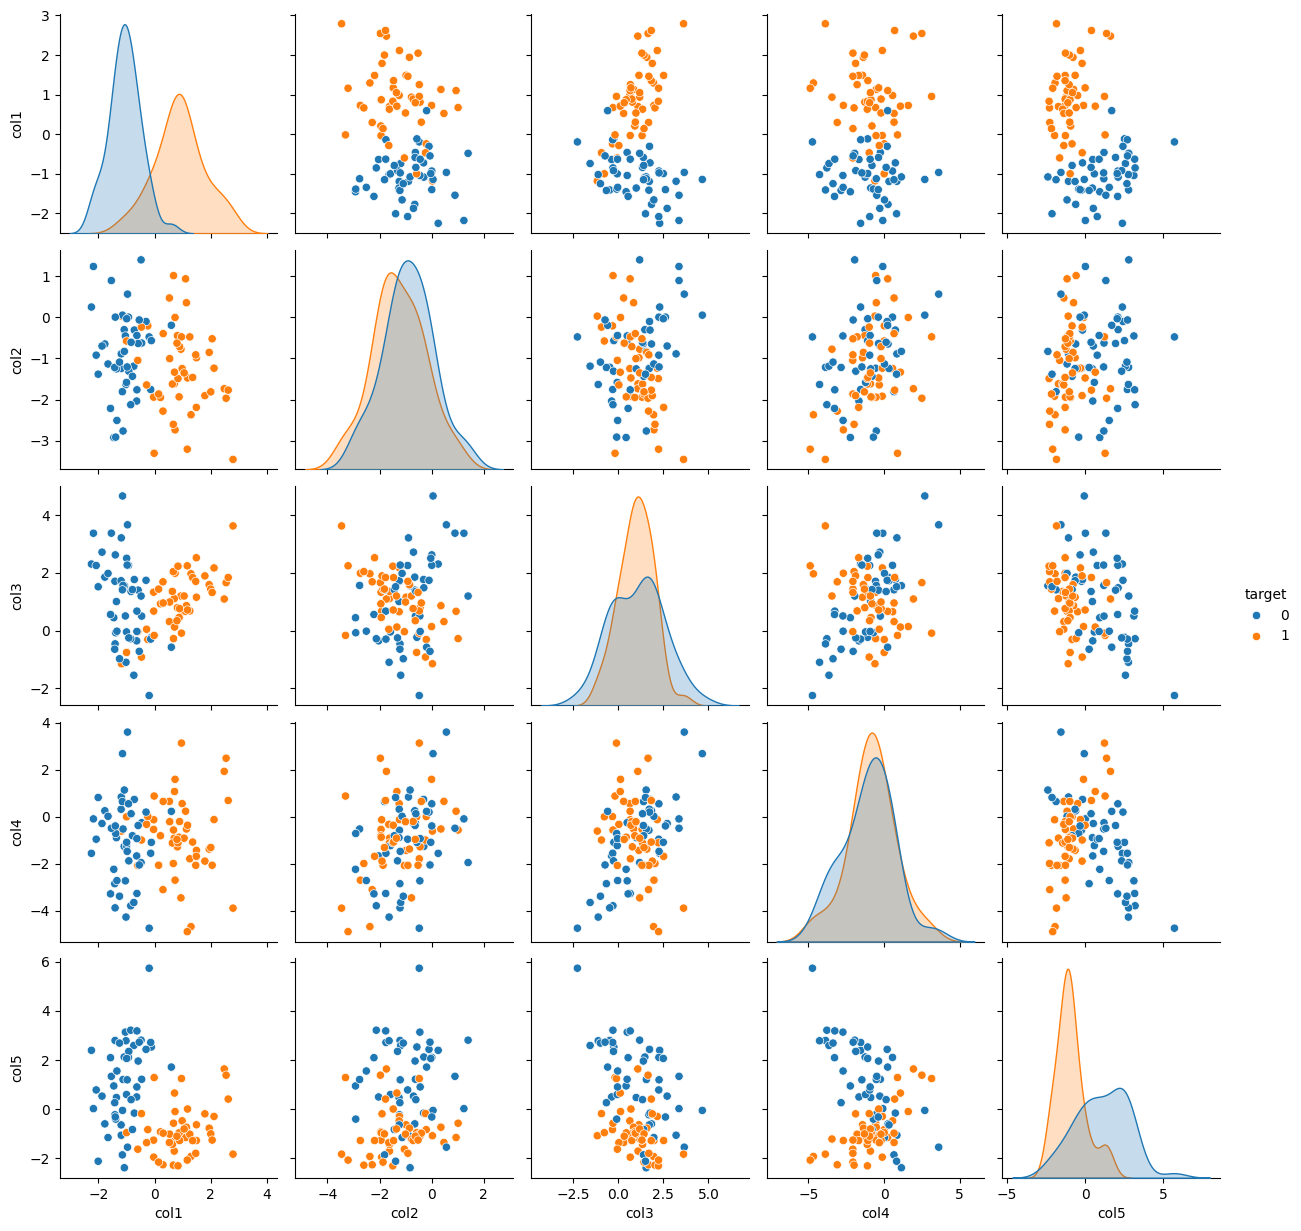

In [17]:
sns.pairplot(df,hue='target')

In [16]:
df = pd.DataFrame(x,columns=['col1','col2','col3','col4','col5'])
df['target'] = y

In [12]:
# function for row sampeling

def sample_rows(df,per):
    return df.sample(int(per * df.shape[0]),replace=True)

In [84]:
# function for collumn sampeling

def sample_col(df, per):
    cols = np.random.choice(df.columns[:-1].tolist(), int(per * (df.shape[1] - 1)), replace=False).tolist() + [df.columns[-1]]
    return df[cols]

In [15]:
# combined sampeling

def combined_sampeling(df,row_per,col_per):
    new_df = sample_rows(df,row_per)
    return sample_col(new_df,col_per)

In [50]:
df1 = sample_rows(df,0.2)

In [51]:
df2 = sample_rows(df,0.2)
df3 = sample_rows(df,0.2)

In [52]:
from sklearn.tree import DecisionTreeClassifier,plot_tree
dc1 = DecisionTreeClassifier()
dc2 = DecisionTreeClassifier()
dc3 = DecisionTreeClassifier()

In [53]:
dc1.fit(df1.iloc[:,0:5],df1['target'])
dc2.fit(df2.iloc[:,0:5],df2['target'])
dc3.fit(df3.iloc[:,0:5],df3['target'])

,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.",'gini'
,"splitter splitter: {""best"", ""random""}, default=""best""The strategy used to choose the split at each node. Supportedstrategies are ""best"" to choose the best split and ""random"" to choosethe best random split.",'best'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: int, float or {""sqrt"", ""log2""}, default=NoneThe number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`... note:: The search for a split does not stop until at least one valid partition of the node samples is found, even if it requires to effectively inspect more than ``max_features`` features.",None
,"random_state random_state: int, RandomState instance or None, default=NoneControls the randomness of the estimator. The features are alwaysrandomly permuted at each split, even if ``splitter`` is set to``""best""``. When ``max_features < n_features``, the algorithm willselect ``max_features`` at random at each split before finding the bestsplit among them. But the best found split may vary across differentruns, even if ``max_features=n_features``. That is the case, if theimprovement of the criterion is identical for several splits and onesplit has to be selected at random. To obtain a deterministic behaviourduring fitting, ``random_state`` has to be fixed to an integer.See :term:`Glossary <random_state>` for details.",None
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow a tree with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsample

[Text(0.6, 0.8333333333333334, 'x[0] <= 0.275\ngini = 0.48\nsamples = 20\nvalue = [12, 8]'),
 Text(0.4, 0.5, 'x[2] <= -0.931\ngini = 0.142\nsamples = 13\nvalue = [12, 1]'),
 Text(0.5, 0.6666666666666667, 'True  '),
 Text(0.2, 0.16666666666666666, 'gini = 0.0\nsamples = 1\nvalue = [0, 1]'),
 Text(0.6, 0.16666666666666666, 'gini = 0.0\nsamples = 12\nvalue = [12, 0]'),
 Text(0.8, 0.5, 'gini = 0.0\nsamples = 7\nvalue = [0, 7]'),
 Text(0.7, 0.6666666666666667, '  False')]

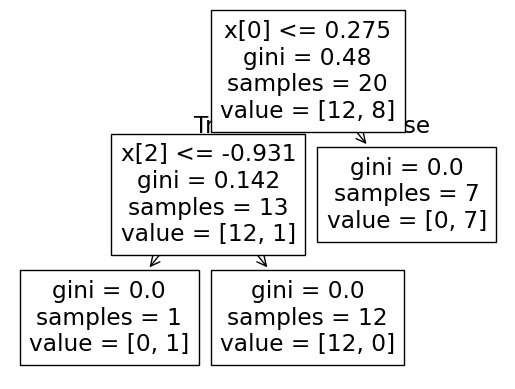

In [54]:
plot_tree(dc1)

[Text(0.6, 0.8333333333333334, 'x[0] <= -0.074\ngini = 0.495\nsamples = 20\nvalue = [11, 9]'),
 Text(0.4, 0.5, 'x[2] <= -0.736\ngini = 0.153\nsamples = 12\nvalue = [11, 1]'),
 Text(0.5, 0.6666666666666667, 'True  '),
 Text(0.2, 0.16666666666666666, 'gini = 0.0\nsamples = 1\nvalue = [0, 1]'),
 Text(0.6, 0.16666666666666666, 'gini = 0.0\nsamples = 11\nvalue = [11, 0]'),
 Text(0.8, 0.5, 'gini = 0.0\nsamples = 8\nvalue = [0, 8]'),
 Text(0.7, 0.6666666666666667, '  False')]

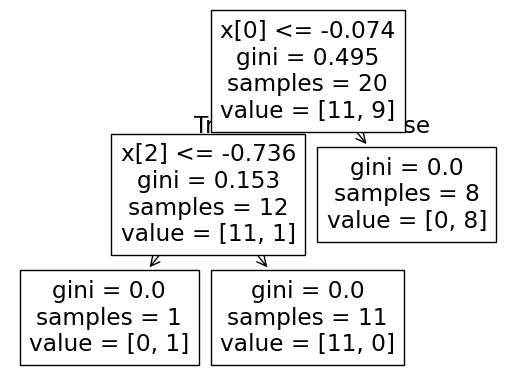

In [55]:
plot_tree(dc2)

[Text(0.5, 0.75, 'x[0] <= -0.603\ngini = 0.455\nsamples = 20\nvalue = [7, 13]'),
 Text(0.25, 0.25, 'gini = 0.0\nsamples = 7\nvalue = [7, 0]'),
 Text(0.375, 0.5, 'True  '),
 Text(0.75, 0.25, 'gini = 0.0\nsamples = 13\nvalue = [0, 13]'),
 Text(0.625, 0.5, '  False')]

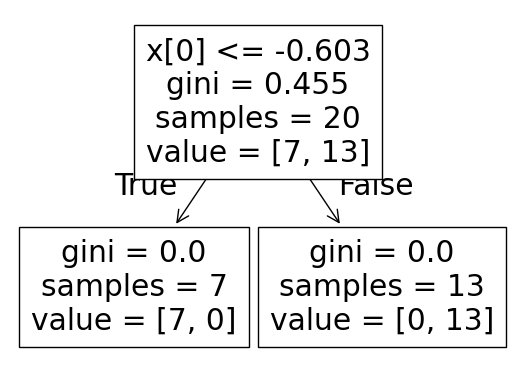

In [56]:
plot_tree(dc3)

In [63]:
 dc1.predict(np.array([-1.411639,	-1.237963,	1.709719,	-0.571062,	-0.226199]).reshape(1,5))

array([0])

In [64]:
 dc2.predict(np.array([-1.411639,	-1.237963,	1.709719,	-0.571062,	-0.226199]).reshape(1,5))

array([0])

In [65]:
 dc3.predict(np.array([-1.411639,	-1.237963,	1.709719,	-0.571062,	-0.226199]).reshape(1,5))

array([0])

In [85]:
df1 = sample_col(df,0.8)
df2 = sample_col(df,0.8)
df3 = sample_col(df,0.8)

In [86]:
df2


,col2,col4,col5,col3,target
0,-1.237963,-0.571062,-0.226199,1.709719,0
1,1.238551,-0.088411,0.022962,3.372563,0
2,-0.299646,-1.258457,2.121562,1.484528,0
3,-0.476287,-4.739289,5.732426,-2.245912,0
4,-0.309013,0.738865,-0.159279,1.770100,0
...,...,...,...,...,...
95,-1.771918,0.694474,0.411177,1.841115,1
96,-1.813526,-1.305921,-1.004102,1.438849,1
97,-0.912493,-2.065126,-1.793517,1.705705,1
98,-0.521321,-2.061219,-1.255125,1.322680,1


In [87]:
from sklearn.tree import DecisionTreeClassifier,plot_tree
dc1 = DecisionTreeClassifier()
dc2 = DecisionTreeClassifier()
dc3 = DecisionTreeClassifier()

In [88]:
dc1.fit(df1.iloc[:,0:4],df1['target'])
dc2.fit(df2.iloc[:,0:4],df2['target'])
dc3.fit(df3.iloc[:,0:4],df3['target'])

,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.",'gini'
,"splitter splitter: {""best"", ""random""}, default=""best""The strategy used to choose the split at each node. Supportedstrategies are ""best"" to choose the best split and ""random"" to choosethe best random split.",'best'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: int, float or {""sqrt"", ""log2""}, default=NoneThe number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`... note:: The search for a split does not stop until at least one valid partition of the node samples is found, even if it requires to effectively inspect more than ``max_features`` features.",None
,"random_state random_state: int, RandomState instance or None, default=NoneControls the randomness of the estimator. The features are alwaysrandomly permuted at each split, even if ``splitter`` is set to``""best""``. When ``max_features < n_features``, the algorithm willselect ``max_features`` at random at each split before finding the bestsplit among them. But the best found split may vary across differentruns, even if ``max_features=n_features``. That is the case, if theimprovement of the criterion is identical for several splits and onesplit has to be selected at random. To obtain a deterministic behaviourduring fitting, ``random_state`` has to be fixed to an integer.See :term:`Glossary <random_state>` for details.",None
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow a tree with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsample

In [91]:
df1

,col5,col1,col3,col4,target
0,-0.226199,-1.411639,1.709719,-0.571062,0
1,0.022962,-2.177106,3.372563,-0.088411,0
2,2.121562,-1.082337,1.484528,-1.258457,0
3,5.732426,-0.193475,-2.245912,-4.739289,0
4,-0.159279,-0.722296,1.770100,0.738865,0
...,...,...,...,...,...
95,0.411177,2.619268,1.841115,0.694474,1
96,-1.004102,1.999088,1.438849,-1.305921,1
97,-1.793517,1.463400,1.705705,-2.065126,1
98,-1.255125,2.047687,1.322680,-2.061219,1


In [93]:
 dc1.predict(np.array([-0.226199,	-1.411639,	1.709719,	-0.571062]).reshape(1,4))

array([0])

In [95]:
 dc2.predict(np.array([-0.226199,	-1.411639,	1.709719,	-0.571062]).reshape(1,4))

array([0])

In [97]:
 dc3.predict(np.array([-0.226199,	-1.411639,	1.709719,	-0.571062]).reshape(1,4))

array([0])

[Text(0.5909090909090909, 0.9, 'x[1] <= -0.075\ngini = 0.5\nsamples = 100\nvalue = [50, 50]'),
 Text(0.36363636363636365, 0.7, 'x[0] <= -0.829\ngini = 0.194\nsamples = 55\nvalue = [49, 6]'),
 Text(0.4772727272727273, 0.8, 'True  '),
 Text(0.18181818181818182, 0.5, 'x[3] <= 0.016\ngini = 0.496\nsamples = 11\nvalue = [6, 5]'),
 Text(0.09090909090909091, 0.3, 'gini = 0.0\nsamples = 5\nvalue = [0, 5]'),
 Text(0.2727272727272727, 0.3, 'gini = 0.0\nsamples = 6\nvalue = [6, 0]'),
 Text(0.5454545454545454, 0.5, 'x[2] <= -0.816\ngini = 0.044\nsamples = 44\nvalue = [43, 1]'),
 Text(0.45454545454545453, 0.3, 'x[2] <= -0.944\ngini = 0.32\nsamples = 5\nvalue = [4, 1]'),
 Text(0.36363636363636365, 0.1, 'gini = 0.0\nsamples = 4\nvalue = [4, 0]'),
 Text(0.5454545454545454, 0.1, 'gini = 0.0\nsamples = 1\nvalue = [0, 1]'),
 Text(0.6363636363636364, 0.3, 'gini = 0.0\nsamples = 39\nvalue = [39, 0]'),
 Text(0.8181818181818182, 0.7, 'x[2] <= -0.424\ngini = 0.043\nsamples = 45\nvalue = [1, 44]'),
 Text(0.704

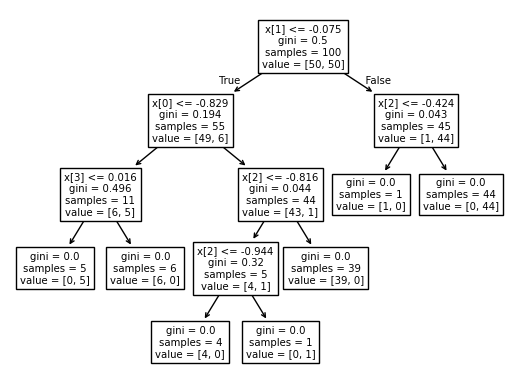

In [98]:
plot_tree(dc1)

[Text(0.6875, 0.9166666666666666, 'x[2] <= 0.015\ngini = 0.5\nsamples = 100\nvalue = [50, 50]'),
 Text(0.5, 0.75, 'x[1] <= 0.016\ngini = 0.366\nsamples = 58\nvalue = [14, 44]'),
 Text(0.59375, 0.8333333333333333, 'True  '),
 Text(0.3125, 0.5833333333333334, 'x[2] <= -0.487\ngini = 0.169\nsamples = 43\nvalue = [4, 39]'),
 Text(0.125, 0.4166666666666667, 'x[2] <= -0.829\ngini = 0.054\nsamples = 36\nvalue = [1, 35]'),
 Text(0.0625, 0.25, 'gini = 0.0\nsamples = 30\nvalue = [0, 30]'),
 Text(0.1875, 0.25, 'x[2] <= -0.815\ngini = 0.278\nsamples = 6\nvalue = [1, 5]'),
 Text(0.125, 0.08333333333333333, 'gini = 0.0\nsamples = 1\nvalue = [1, 0]'),
 Text(0.25, 0.08333333333333333, 'gini = 0.0\nsamples = 5\nvalue = [0, 5]'),
 Text(0.5, 0.4166666666666667, 'x[2] <= -0.207\ngini = 0.49\nsamples = 7\nvalue = [3, 4]'),
 Text(0.4375, 0.25, 'x[1] <= -0.254\ngini = 0.375\nsamples = 4\nvalue = [3, 1]'),
 Text(0.375, 0.08333333333333333, 'gini = 0.0\nsamples = 3\nvalue = [3, 0]'),
 Text(0.5, 0.0833333333333

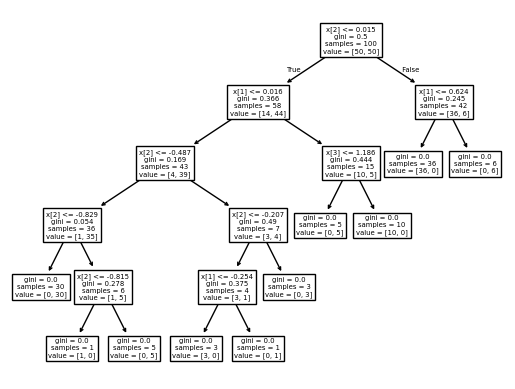

In [99]:
plot_tree(dc2)

[Text(0.6, 0.9375, 'x[2] <= -0.075\ngini = 0.5\nsamples = 100\nvalue = [50, 50]'),
 Text(0.4, 0.8125, 'x[3] <= 0.248\ngini = 0.194\nsamples = 55\nvalue = [49, 6]'),
 Text(0.5, 0.875, 'True  '),
 Text(0.3, 0.6875, 'x[0] <= -0.659\ngini = 0.397\nsamples = 22\nvalue = [16, 6]'),
 Text(0.2, 0.5625, 'x[1] <= -1.068\ngini = 0.198\nsamples = 18\nvalue = [16, 2]'),
 Text(0.1, 0.4375, 'gini = 0.0\nsamples = 12\nvalue = [12, 0]'),
 Text(0.3, 0.4375, 'x[1] <= -0.807\ngini = 0.444\nsamples = 6\nvalue = [4, 2]'),
 Text(0.2, 0.3125, 'gini = 0.0\nsamples = 1\nvalue = [0, 1]'),
 Text(0.4, 0.3125, 'x[1] <= -0.339\ngini = 0.32\nsamples = 5\nvalue = [4, 1]'),
 Text(0.3, 0.1875, 'gini = 0.0\nsamples = 3\nvalue = [3, 0]'),
 Text(0.5, 0.1875, 'x[0] <= -1.518\ngini = 0.5\nsamples = 2\nvalue = [1, 1]'),
 Text(0.4, 0.0625, 'gini = 0.0\nsamples = 1\nvalue = [1, 0]'),
 Text(0.6, 0.0625, 'gini = 0.0\nsamples = 1\nvalue = [0, 1]'),
 Text(0.4, 0.5625, 'gini = 0.0\nsamples = 4\nvalue = [0, 4]'),
 Text(0.5, 0.6875, '

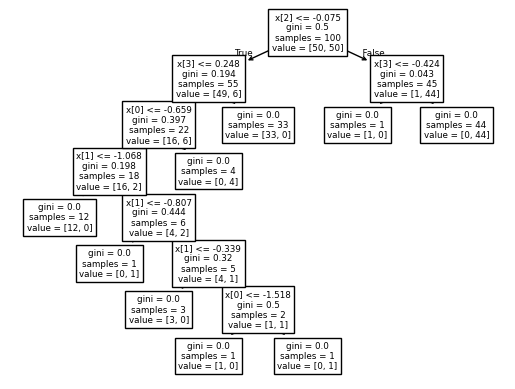

In [101]:
plot_tree(dc3)